<div dir="rtl">

# 02 · עיבוד מקדים ומודלי סיווג

**הסדר (כדי למנוע Data Leakage, שיעור 1):**
1. לפצל ל־train/test **לפני הכול**, עם `stratify`.
2. כל העיבוד (One-hot, Scaling, Resampling) בתוך `Pipeline`, כך שהוא לומד רק מה־train.
3. להשוות מודלים ושיטות איזון ב־Cross-validation על ה־train בלבד (שיעור 2: Resampling בתוך כל fold).
4. רק בסוף: הערכה אחת על ה־test.

**מאיזה שיעור כל דבר:**
| מה | שיעור |
|---|---|
| Confusion matrix, Precision, Recall, F1, Macro F1, למה לא Accuracy | 1 |
| Random Oversampling, SMOTE, Tomek Links, NearMiss, SMOTEENN, Class weights | 1 |
| `stratify`, Data Leakage, Resampling רק על ה־train | 1 |
| Resampling בתוך כל fold עם Pipeline של imblearn, הזזת סף, PR-AUC | 2 (בוחן החזרה) |
| MLP, Scaling לטווח 0–1, Early stopping, XGBoost לדאטה טבלאי | 2 |
| השלמת ערכים חסרים בחציון (SimpleImputer), הסרת כפילויות, StandardScaler מול MinMaxScaler, PCA | 3 |
| רגרסיה לוגיסטית, עץ החלטה, Random Forest, KNN | מודלים מהסמסטר הקודם, שהמרצה הזכיר בשיעורים 1–2 |

> כל תא קוד במחברת נכתב בעזרת Claude, ולכן מסומן `### CODE BY CLAUDE ###` לפי הנחיות המרצה.

</div>

In [1]:
### CODE BY CLAUDE ###
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # כדי שאפשר יהיה לייבא את src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import (load_raw, add_features, get_xy, build_preprocessor, FIGURES,
                      RANDOM_STATE, TARGET, SEVERITY_NAMES, CATEGORICAL, NUMERIC, BINARY,
                      label, COLUMN_NAMES)

sns.set_theme(style="whitegrid")
FIGURES.mkdir(exist_ok=True)
SEV_ORDER = ["קטלנית", "קשה", "קלה"]
SEV_COLORS = ["#a3262c", "#e08a2c", "#7a8aa0"]

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (f1_score, recall_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer)
from sklearn.preprocessing import label_binarize
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import TomekLinks, NearMiss
from imblearn.combine import SMOTEENN
from xgboost import XGBClassifier

# שמות בעברית לטבלאות התוצאות
COLS_HE = {"model": "מודל", "balance": "איזון", "f1_macro": "F1-macro", "recall_fatal": "Recall קטלנית",
           "pr_auc": "PR-AUC", "accuracy": "Accuracy"}
BALANCE_HE = {"none": "בלי טיפול", "class_weight": "class_weight", "smote": "SMOTE"}
####

<div dir="rtl">

## 1. פיצול train/test (שיעור 1: stratify)
בלי 1,235 התאונות שאין בהן פרטי דרך (ראו `01_eda`, סעיף 6). ל־20 תאונות אין קואורדינטות: הן **נשארות**, וה־X וה־Y שלהן מושלמים בחציון בתוך ה־Pipeline (שיעור 3).
80/20, עם `stratify=y`: בשני החלקים יהיה אותו אחוז של קטלניות (כ־5.7%).

</div>

In [2]:
### CODE BY CLAUDE ###
X, y = get_xy(load_raw())
# מחלקות כ־0/1/2 (‏XGBoost דורש תוויות שמתחילות ב־0): ‏0 = קטלנית, 1 = קשה, 2 = קלה
y = y - 1
CLASS_NAMES = SEV_ORDER

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, " test:", X_test.shape)
print(pd.DataFrame({"% ב־train": y_train.value_counts(normalize=True).sort_index().mul(100).round(1),
                    "% ב־test": y_test.value_counts(normalize=True).sort_index().mul(100).round(1)},
                   ).set_axis(CLASS_NAMES))
####

train: (5664, 34)  test: (1416, 34)
        % ב־train  % ב־test
קטלנית        5.7       5.6
קשה          21.2      21.3
קלה          73.1      73.1


<div dir="rtl">

## 2. העיבוד המקדים
- **קטגוריות (28):** One-hot. כל קוד הופך לעמודה של 0/1, כי הקודים הם שמות של קטגוריות ולא כמויות.
- **מספריות (X, Y):** קודם השלמת חסרים בחציון (`SimpleImputer`, שיעור 3), ואז Scaling לטווח 0–1 עם `MinMaxScaler` (שיעורים 2–3). ה־fit רק על ה־train (זה קורה לבד בתוך ה־Pipeline).
- **דגלים (4):** עירוני, בצומת (שניהם מפוצלים מ־`SUG_DEREH`), יש רחוב, יש מספר כביש. כבר 0/1, עוברים כמו שהם.

</div>

In [3]:
### CODE BY CLAUDE ###
prep = build_preprocessor().fit(X_train)
print("מספר פיצ'רים אחרי One-hot:", prep.transform(X_train.head()).shape[1])
####

מספר פיצ'רים אחרי One-hot: 290


<div dir="rtl">

## 3. המדדים (שיעורים 1–2)
- **Macro F1 (המדד הראשי, שיעור 1):** ממוצע של F1 בכל מחלקה. כך הקטלנית שוקלת כמו האחרות, למרות שהיא 5% מהדאטה.
- **Recall של קטלנית (שיעור 1):** כמה מהתאונות הקטלניות המודל תפס.
- **PR-AUC (שיעור 2):** כמה טוב המודל מפריד בין המחלקות, בלי תלות בסף. מתאים לדאטה לא מאוזן.
- Accuracy מוצג רק להשוואה. בשיעור 1 ראינו שבדאטה לא מאוזן הוא מטעה.

</div>

In [4]:
### CODE BY CLAUDE ###
def pr_auc_macro(y_true, proba):
    y_bin = label_binarize(y_true, classes=[0, 1, 2])
    return average_precision_score(y_bin, proba, average="macro")

SCORING = {
    "f1_macro": "f1_macro",
    "recall_fatal": make_scorer(recall_score, labels=[0], average="macro"),
    "pr_auc": make_scorer(pr_auc_macro, response_method="predict_proba"),
    "accuracy": "accuracy",
}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
####

<div dir="rtl">

## 4. ניסוי 1: 6 מודלים × 3 שיטות איזון
- **בלי טיפול.**
- **class_weight (שיעור 1):** טעות על מחלקה קטנה "עולה" יותר (`class_weight="balanced"`, וב־XGBoost אותו דבר דרך `sample_weight`). ל־MLP ול־KNN אין אפשרות כזו.
- **SMOTE (שיעור 1):** **בתוך** הפייפליין של imblearn, כך שבכל fold הוא רץ רק על חלק האימון (שיעור 2).
- ב־MLP: ‏`early_stopping=True` (שיעור 2).

</div>

In [5]:
### CODE BY CLAUDE ###
def make_models(balance):
    cw = "balanced" if balance == "class_weight" else None
    models = {
        "LogisticRegression": LogisticRegression(max_iter=2000, class_weight=cw, random_state=RANDOM_STATE),
        "DecisionTree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight=cw, random_state=RANDOM_STATE),
        "RandomForest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight=cw, n_jobs=-1, random_state=RANDOM_STATE),
        "XGBoost": XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05,
                                 eval_metric="mlogloss", n_jobs=-1, random_state=RANDOM_STATE),
    }
    if balance != "class_weight":   # לשני המודלים האלה אין class_weight
        models["MLP"] = MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                      max_iter=300, random_state=RANDOM_STATE)
        models["KNN"] = KNeighborsClassifier(n_neighbors=15)
    return models

def make_pipeline(model, sampler=None):
    steps = [("prep", build_preprocessor())]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", model))
    return Pipeline(steps)

rows = []
for balance in ["none", "class_weight", "smote"]:
    for name, model in make_models(balance).items():
        params = {}
        if balance == "class_weight" and name == "XGBoost":
            params = {"clf__sample_weight": compute_sample_weight("balanced", y_train)}
        sampler = SMOTE(random_state=RANDOM_STATE) if balance == "smote" else None
        res = cross_validate(make_pipeline(model, sampler), X_train, y_train, cv=CV,
                             scoring=SCORING, params=params, n_jobs=1)
        rows.append({"model": name, "balance": BALANCE_HE[balance],
                     **{m: res[f"test_{m}"].mean() for m in SCORING}})
        print(f"{name:20s} {BALANCE_HE[balance]:13s} F1-macro={rows[-1]['f1_macro']:.3f}  Recall קטלנית={rows[-1]['recall_fatal']:.3f}")

results = pd.DataFrame(rows).round(3).sort_values("f1_macro", ascending=False)
results.rename(columns=COLS_HE).to_csv(FIGURES / "experiment1_results.csv", index=False, encoding="utf-8-sig")
results.rename(columns=COLS_HE)
####

LogisticRegression   בלי טיפול     F1-macro=0.418  Recall קטלנית=0.134


DecisionTree         בלי טיפול     F1-macro=0.387  Recall קטלנית=0.065


RandomForest         בלי טיפול     F1-macro=0.315  Recall קטלנית=0.009


XGBoost              בלי טיפול     F1-macro=0.383  Recall קטלנית=0.084


MLP                  בלי טיפול     F1-macro=0.346  Recall קטלנית=0.062


KNN                  בלי טיפול     F1-macro=0.318  Recall קטלנית=0.019


... (7 outputs left out)

XGBoost              SMOTE         F1-macro=0.343  Recall קטלנית=0.062


MLP                  SMOTE         F1-macro=0.420  Recall קטלנית=0.184


KNN                  SMOTE         F1-macro=0.286  Recall קטלנית=0.452


,מודל,איזון,F1-macro,Recall קטלנית,PR-AUC,Accuracy
8,RandomForest,class_weight,0.457,0.380,0.453,0.627
9,XGBoost,class_weight,0.436,0.418,0.456,0.594
6,LogisticRegression,class_weight,0.434,0.479,0.445,0.577
10,LogisticRegression,SMOTE,0.426,0.480,0.435,0.565
11,DecisionTree,SMOTE,0.425,0.386,0.418,0.621
14,MLP,SMOTE,0.420,0.184,0.414,0.657
0,LogisticRegression,בלי טיפול,0.418,0.134,0.476,0.728
12,RandomForest,SMOTE,0.404,0.103,0.459,0.722
1,DecisionTree,בלי טיפול,0.387,0.065,0.434,0.726
3,XGBoost,בלי טיפול,0.383,0.084,0.474,0.731


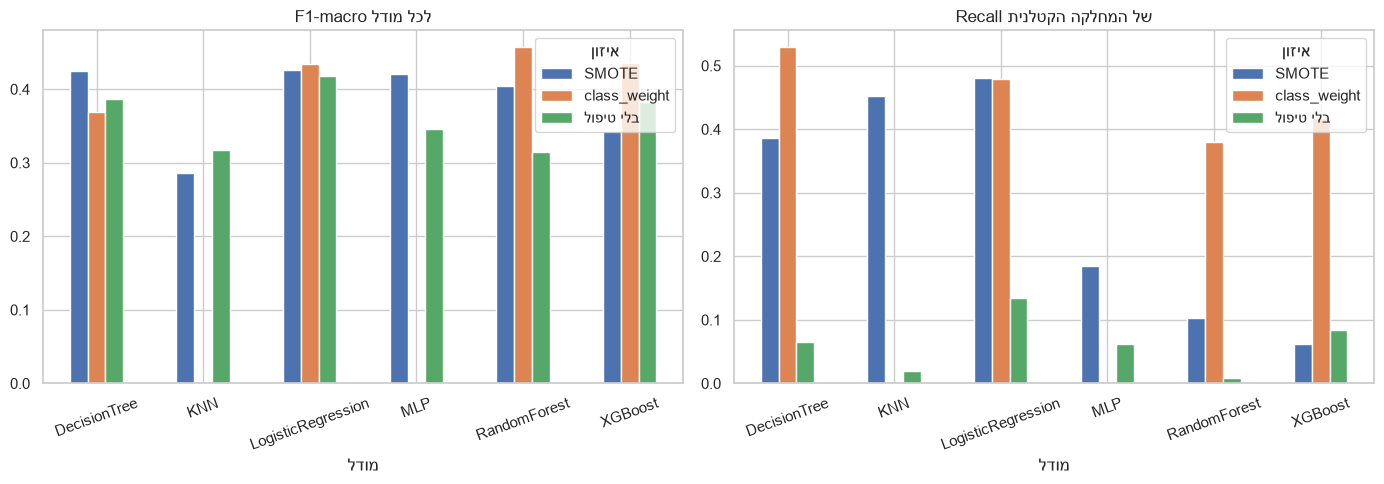

In [6]:
### CODE BY CLAUDE ###
pivot = results.pivot(index="model", columns="balance", values="f1_macro")
pivot_r = results.pivot(index="model", columns="balance", values="recall_fatal")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pivot.plot.bar(ax=axes[0], rot=20); axes[0].set_title("F1-macro לכל מודל")
pivot_r.plot.bar(ax=axes[1], rot=20); axes[1].set_title("Recall של המחלקה הקטלנית")
for ax in axes:
    ax.set_xlabel("מודל"); ax.legend(title="איזון")
plt.tight_layout(); plt.savefig(FIGURES / "09_experiment1.png", dpi=150); plt.show()
####

<div dir="rtl">

**מה לשים לב (לפגישה):**
- בלי טיפול באיזון, ה־Recall של הקטלנית קרוב ל־0: המודלים פשוט לא מנבאים "קטלנית".
- class_weight ו־SMOTE מעלים מאוד את ה־Recall של הקטלנית, ובדרך כלל מורידים את ה־Accuracy. זה ה־trade-off משיעור 1.

</div>

<div dir="rtl">

## 5. ניסוי 2: כל שיטות ה־Resampling משיעור 1, על המודל המוביל
לוקחים את המודל עם ה־F1-macro הכי גבוה בניסוי 1, ומשווים עליו את כל השיטות שהוצגו בשיעור 1:
Random Oversampling, ‏SMOTE, ‏Tomek Links, ‏NearMiss, ‏SMOTEENN, ו־class_weight. הכול בתוך הפייפליין, כך שכל שיטה רצה רק על ה־train של כל fold.

</div>

In [7]:
### CODE BY CLAUDE ###
best_model_name = results.iloc[0]["model"]
print("המודל המוביל מניסוי 1:", best_model_name)

samplers = {
    "בלי טיפול": None,
    "Random Oversampling": RandomOverSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
    "Tomek Links": TomekLinks(),
    "NearMiss": NearMiss(version=1),
    "SMOTEENN": SMOTEENN(random_state=RANDOM_STATE),
}
rows2 = []
for balance_name, sampler in samplers.items():
    model = make_models("none")[best_model_name]
    res = cross_validate(make_pipeline(model, sampler), X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1)
    rows2.append({"איזון": balance_name, **{COLS_HE[m]: res[f"test_{m}"].mean() for m in SCORING}})
    print(f"{balance_name:20s} F1-macro={rows2[-1]['F1-macro']:.3f}")
# class_weight מניסוי 1, לאותו מודל
cw_row = results[(results["model"] == best_model_name) & (results["balance"] == "class_weight")].iloc[0]
rows2.append({"איזון": "class_weight", **{COLS_HE[m]: cw_row[m] for m in SCORING}})
resampling = pd.DataFrame(rows2).round(3).sort_values("F1-macro", ascending=False)
resampling.to_csv(FIGURES / "experiment2_resampling.csv", index=False, encoding="utf-8-sig")
resampling
####

המודל המוביל מניסוי 1: RandomForest


בלי טיפול            F1-macro=0.315


Random Oversampling  F1-macro=0.454


SMOTE                F1-macro=0.404


Tomek Links          F1-macro=0.315


NearMiss             F1-macro=0.263


SMOTEENN             F1-macro=0.347


,איזון,F1-macro,Recall קטלנית,PR-AUC,Accuracy
6,class_weight,0.457,0.380,0.453,0.627
1,Random Oversampling,0.454,0.196,0.455,0.689
2,SMOTE,0.404,0.103,0.459,0.722
5,SMOTEENN,0.347,0.206,0.434,0.409
0,בלי טיפול,0.315,0.009,0.475,0.732
3,Tomek Links,0.315,0.028,0.475,0.732
4,NearMiss,0.263,0.651,0.382,0.292


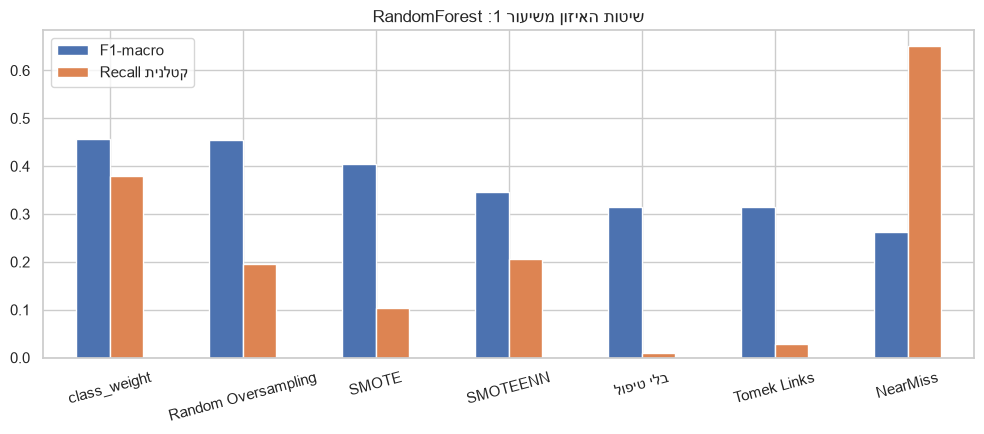

In [8]:
### CODE BY CLAUDE ###
ax = resampling.set_index("איזון")[["F1-macro", "Recall קטלנית"]].plot.bar(figsize=(10, 4.5), rot=15)
ax.set_title(f"שיטות האיזון משיעור 1: {best_model_name}")
ax.set_xlabel("")
plt.tight_layout(); plt.savefig(FIGURES / "10_resampling_methods.png", dpi=150); plt.show()
####

<div dir="rtl">

**מה לשים לב:** NearMiss זורק הרבה דוגמאות מהרוב, ולכן ה־Recall של קטלנית עולה אבל הדיוק על שאר המחלקות נפגע.
Tomek Links מוחק רק מעט נקודות "גבול", ולכן הוא קרוב ל"בלי טיפול". זה בדיוק מה שראינו בשיעור 1.

</div>

<div dir="rtl">

## 6. הערכה סופית על ה־test
בוחרים את השילוב (מודל + שיטת איזון) עם ה־F1-macro הכי גבוה ב־CV, מאמנים אותו על כל ה־train, ובודקים **פעם אחת** על ה־test.

</div>

In [9]:
### CODE BY CLAUDE ###
# הבחירה לפי ה־CV על ה־train, אף פעם לא לפי ה־test
best_balance = resampling.iloc[0]["איזון"]
if best_balance == "class_weight":
    final = make_pipeline(make_models("class_weight")[best_model_name])
    fit_params = {"clf__sample_weight": compute_sample_weight("balanced", y_train)} if best_model_name == "XGBoost" else {}
else:
    final = make_pipeline(make_models("none")[best_model_name], samplers[best_balance])
    fit_params = {}
final.fit(X_train, y_train, **fit_params)
print("המודל הסופי:", best_model_name, "+", best_balance)

proba = final.predict_proba(X_test)
pred = proba.argmax(axis=1)
test_results = pd.DataFrame([{"מודל": best_model_name, "איזון": best_balance,
                              "F1-macro": f1_score(y_test, pred, average="macro"),
                              "Recall קטלנית": recall_score(y_test, pred, labels=[0], average="macro"),
                              "PR-AUC": pr_auc_macro(y_test, proba),
                              "Accuracy": (pred == y_test).mean()}]).round(3)
test_results.to_csv(FIGURES / "test_results.csv", index=False, encoding="utf-8-sig")
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=3))
test_results
####

המודל הסופי: RandomForest + class_weight


              precision    recall  f1-score   support

      קטלנית      0.179     0.338     0.234        80
         קשה      0.287     0.352     0.316       301
         קלה      0.827     0.716     0.767      1035

    accuracy                          0.617      1416
   macro avg      0.431     0.469     0.439      1416
weighted avg      0.676     0.617     0.641      1416



,מודל,איזון,F1-macro,Recall קטלנית,PR-AUC,Accuracy
0,RandomForest,class_weight,0.439,0.338,0.444,0.617


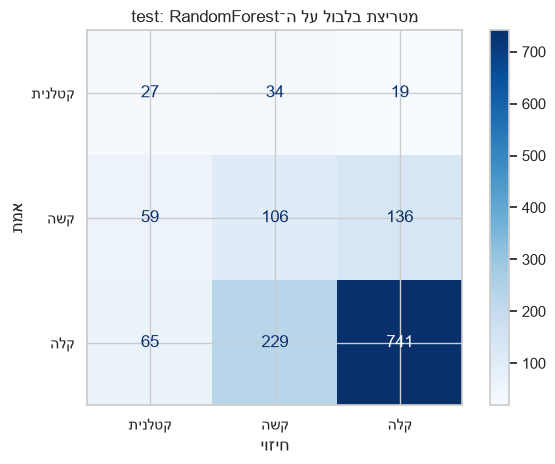

In [10]:
### CODE BY CLAUDE ###
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASS_NAMES).plot(cmap="Blues")
plt.title(f"מטריצת בלבול על ה־test: {best_model_name}")
plt.xlabel("חיזוי"); plt.ylabel("אמת")
plt.tight_layout(); plt.savefig(FIGURES / "11_confusion_matrix.png", dpi=150); plt.show()
####

<div dir="rtl">

## 7. הזזת סף לקטלנית (שיעור 2)
המודל נותן הסתברות לכל מחלקה. ברירת המחדל: לבחור את הגבוהה ביותר.
כאן מכריזים "קטלנית" כבר כשההסתברות שלה עוברת סף נמוך יותר, ובודקים מה קורה ל־Recall ול־Precision שלה.
⚠️ בפרויקט עצמו את הסף בוחרים על validation (או CV) ולא על ה־test. כאן זה רק להמחשה של ה־trade-off.

</div>

In [11]:
### CODE BY CLAUDE ###
rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]:
    pred_t = proba.argmax(axis=1)
    pred_t[proba[:, 0] >= t] = 0
    rows.append({"סף": t,
                 "Recall קטלנית": recall_score(y_test, pred_t, labels=[0], average="macro"),
                 "Precision קטלנית": ((pred_t == 0) & (y_test == 0)).sum() / max((pred_t == 0).sum(), 1),
                 "F1-macro": f1_score(y_test, pred_t, average="macro")})
pd.DataFrame(rows).round(3)
####

,סף,Recall קטלנית,Precision קטלנית,F1-macro
0,0.50,0.338,0.179,0.439
1,0.40,0.338,0.173,0.434
2,0.30,0.538,0.169,0.432
3,0.20,0.800,0.116,0.352
4,0.15,0.875,0.095,0.306
5,0.10,0.950,0.079,0.235


<div dir="rtl">

## 8. ניתוח שגיאות: על אילו תאונות קטלניות המודל טעה?
(ניתוח שגיאות נדרש במסמך הפרויקט.) משווים את הקטלניות שהמודל **פספס** לאלה שהוא **תפס**, בכמה פיצ'רים מרכזיים.

</div>

In [12]:
### CODE BY CLAUDE ###
fatal_test = X_test[y_test == 0].copy()
fatal_test["נתפסה"] = pred[y_test.values == 0] == 0
print(f"תאונות קטלניות ב־test: {len(fatal_test)}, המודל תפס: {fatal_test['נתפסה'].sum()}")
for col in ["URBAN", "JUNCTION", "YOM_LAYLA", "SUG_TEUNA", "HAS_ROAD_NUMBER"]:
    print(f"\n{COLUMN_NAMES.get(col, col)}: אחוז מהתאונות הקטלניות בכל ערך, נתפסו מול פוספסו")
    names = fatal_test[col].map(lambda c: label(col, c)) if col != "HAS_ROAD_NUMBER" else fatal_test[col].map({1: "יש", 0: "אין"})
    print(pd.crosstab(names, fatal_test["נתפסה"], normalize="columns").mul(100).round(0)
          .rename(columns={True: "נתפסו", False: "פוספסו"}))
####

תאונות קטלניות ב־test: 80, המודל תפס: 27

עירוני / לא עירוני: אחוז מהתאונות הקטלניות בכל ערך, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
URBAN                   
לא עירוני    49.0   81.0
עירוני       51.0   19.0

צומת / לא צומת: אחוז מהתאונות הקטלניות בכל ערך, נתפסו מול פוספסו
נתפסה     פוספסו  נתפסו
JUNCTION               
בצומת       38.0   19.0
לא בצומת    62.0   81.0

יום/לילה: אחוז מהתאונות הקטלניות בכל ערך, נתפסו מול פוספסו
נתפסה      פוספסו  נתפסו
YOM_LAYLA               
יום          55.0   52.0
לילה         45.0   48.0

סוג התאונה: אחוז מהתאונות הקטלניות בכל ערך, נתפסו מול פוספסו
נתפסה                         פוספסו  נתפסו
SUG_TEUNA                                  
אחר                              0.0    4.0
החלקה                            0.0    7.0
התהפכות                          6.0    7.0
התנגשות חזית באחור               2.0   19.0
התנגשות חזית בחזית              11.0   11.0
התנגשות חזית בצד                32.0    7.0
התנגשות עם עצם דומם              8.0    4.0
התנגשות צ

<div dir="rtl">

## 9. ניסוי 3: בעיה בינארית, חמורה (קטלנית + קשה) מול קלה
שאלה: האם קל יותר להבדיל בין "חמורה" ל"קלה", מאשר להפריד גם בין קטלנית לקשה?

</div>

In [13]:
### CODE BY CLAUDE ###
yb_train = (y_train <= 1).astype(int)   # 1 = קטלנית או קשה
bin_rows = []
for name in ["LogisticRegression", "RandomForest", "XGBoost"]:
    model = make_models("class_weight")[name]
    fit_params = {"clf__sample_weight": compute_sample_weight("balanced", yb_train)} if name == "XGBoost" else {}
    res = cross_validate(make_pipeline(model), X_train, yb_train, cv=CV, params=fit_params,
                         scoring={"f1_macro": "f1_macro", "recall_severe": "recall", "pr_auc": "average_precision"})
    bin_rows.append({"מודל": name, "F1-macro": res["test_f1_macro"].mean(),
                     "Recall חמורה": res["test_recall_severe"].mean(), "PR-AUC": res["test_pr_auc"].mean()})
pd.DataFrame(bin_rows).round(3)
####

,מודל,F1-macro,Recall חמורה,PR-AUC
0,LogisticRegression,0.637,0.626,0.480
1,RandomForest,0.641,0.552,0.496
2,XGBoost,0.636,0.591,0.488


<div dir="rtl">

## 10. ניסוי 4: מה קורה אם משאירים את 1,235 התאונות בלי פרטי דרך? (שיעור 1: Data Leakage)
ב־EDA (סעיף 6) ראינו ש־77% מהן "קשות". אם משאירים אותן, המודל לומד את הארטיפקט, והציון "מתנפח".

</div>

In [14]:
### CODE BY CLAUDE ###
X_all, y_all = get_xy(load_raw(), drop_missing_details=False)
y_all = y_all - 1
Xa_train, Xa_test, ya_train, ya_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
art_rows = []
for data_name, (Xt, yt) in {"בלי השורות האלה (הניסוי הראשי)": (X_train, y_train),
                        "עם השורות האלה": (Xa_train, ya_train)}.items():
    pipe = make_pipeline(make_models("class_weight")["XGBoost"])
    res = cross_validate(pipe, Xt, yt, cv=CV, scoring=SCORING,
                         params={"clf__sample_weight": compute_sample_weight("balanced", yt)})
    art_rows.append({"הדאטה": data_name, "שורות": len(Xt),
                     **{COLS_HE[m]: res[f"test_{m}"].mean() for m in SCORING}})
pd.DataFrame(art_rows).round(3)
####

,הדאטה,שורות,F1-macro,Recall קטלנית,PR-AUC,Accuracy
0,בלי השורות האלה (הניסוי הראשי),5664,0.436,0.418,0.456,0.594
1,עם השורות האלה,6652,0.517,0.500,0.565,0.659


<div dir="rtl">

**מה לראות:** עם השורות האלה הציון גבוה יותר, בעיקר כי קל לזהות "קשה" לפי פרטים חסרים. זה לא שיפור אמיתי,
ולכן הניסוי הראשי בלעדיהן. בדו"ח זה ממצא טוב לסעיף ניתוח השגיאות / איכות הדאטה.

</div>

<div dir="rtl">

## 11. ניסוי 5: נרמול והפחתת ממדים (שיעור 3)
**נרמול:** בשיעור 3 המרצה אמר שמודלים שעובדים עם מרחקים או גרדיאנטים (KNN, רגרסיה לוגיסטית, רשת נוירונים) צריכים נרמול, ועצי החלטה לא.
משווים `MinMaxScaler` (טווח 0–1) ל־`StandardScaler` (‏z-score: ממוצע 0, סטיית תקן 1) על שלושת המודלים הרגישים.
אצלנו רק X ו־Y מספריים, וכל השאר One-hot של 0/1. לכן השאלה היא בעיקר כמה "משקל" מקבל המיקום לעומת הקטגוריות:
ב־MinMax הוא בטווח 0–1 כמו הדגלים, וב־Standard הוא יכול להגיע ל־±3.

</div>

In [15]:
### CODE BY CLAUDE ###
SCALER_HE = {"minmax": "MinMaxScaler", "standard": "StandardScaler"}
SENSITIVE = {"LogisticRegression": "class_weight", "KNN": "none", "MLP": "none"}

def make_pipeline_with(prep, model, extra_steps=()):
    return Pipeline([("prep", prep), *extra_steps, ("clf", model)])

rows5 = []
for scaler in ["minmax", "standard"]:
    for name, balance in SENSITIVE.items():
        pipe = make_pipeline_with(build_preprocessor(scaler), make_models(balance)[name])
        res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1)
        rows5.append({"נרמול": SCALER_HE[scaler], "מודל": name,
                      **{COLS_HE[m]: res[f"test_{m}"].mean() for m in SCORING}})
scaling = pd.DataFrame(rows5).round(3)
scaling.to_csv(FIGURES / "experiment5_scaling.csv", index=False, encoding="utf-8-sig")
scaling.pivot(index="מודל", columns="נרמול", values=["F1-macro", "Recall קטלנית"])
####

F1-macro                Recall קטלנית               
נרמול              MinMaxScaler StandardScaler  MinMaxScaler StandardScaler
מודל                                                                       
KNN                       0.318          0.313         0.019          0.012
LogisticRegression        0.434          0.432         0.479          0.476
MLP                       0.346          0.330         0.062          0.034

<div dir="rtl">

**PCA (שיעור 3):** מחליף את כל הפיצ'רים בכמה "רכיבים ראשיים" חדשים, שתופסים את רוב השונות.
המרצה הדגיש שני דברים: לנרמל לפני (אחרת עמודה עם טווח גדול "משתלטת"), ושעל עמודות קטגוריאליות של 0/1 PCA עובד פחות טוב.
אצלנו כמעט הכול One-hot, אז בודקים: כמה רכיבים צריך כדי לשמור 80%–95% מהשונות, והאם המודלים משתפרים או נפגעים.
ה־PCA בתוך ה־Pipeline, כך שהוא לומד רק מה־train של כל fold (שיעור 1: Data Leakage).

</div>

מספר הפיצ'רים אחרי One-hot: 290
כדי לשמור 80% מהשונות צריך 52 רכיבים
כדי לשמור 90% מהשונות צריך 77 רכיבים
כדי לשמור 95% מהשונות צריך 102 רכיבים


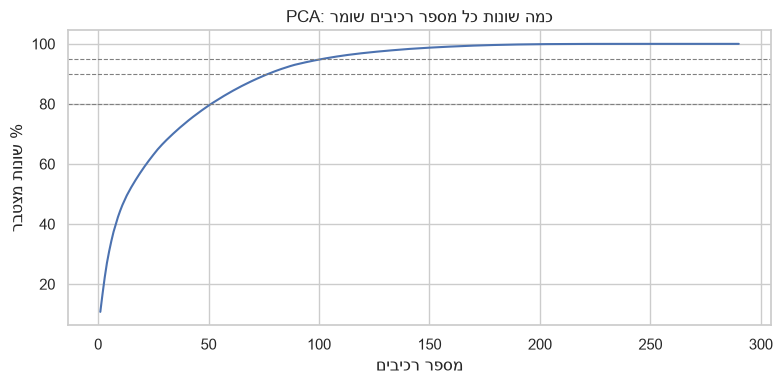

In [16]:
### CODE BY CLAUDE ###
from sklearn.decomposition import PCA

Z_train = build_preprocessor(dense=True).fit_transform(X_train)
cum = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Z_train).explained_variance_ratio_)
print("מספר הפיצ'רים אחרי One-hot:", Z_train.shape[1])
for share in [0.8, 0.9, 0.95]:
    print(f"כדי לשמור {share:.0%} מהשונות צריך {np.searchsorted(cum, share) + 1} רכיבים")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cum) + 1), cum * 100)
for share in [80, 90, 95]:
    ax.axhline(share, ls="--", lw=0.8, color="gray")
ax.set_xlabel("מספר רכיבים"); ax.set_ylabel("% שונות מצטבר"); ax.set_title("PCA: כמה שונות כל מספר רכיבים שומר")
plt.tight_layout(); plt.savefig(FIGURES / "12_pca_variance.png", dpi=150); plt.show()
####

In [17]:
### CODE BY CLAUDE ###
rows_pca = []
for name, balance in [("LogisticRegression", "class_weight"), ("KNN", "none")]:
    for k in [None, 10, 30, 60]:
        extra = [] if k is None else [("pca", PCA(n_components=k, random_state=RANDOM_STATE))]
        pipe = make_pipeline_with(build_preprocessor(dense=True), make_models(balance)[name], extra)
        res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=1)
        rows_pca.append({"מודל": name, "רכיבי PCA": "בלי PCA" if k is None else k,
                         **{COLS_HE[m]: res[f"test_{m}"].mean() for m in SCORING}})
pca_results = pd.DataFrame(rows_pca).round(3)
pca_results.to_csv(FIGURES / "experiment5_pca.csv", index=False, encoding="utf-8-sig")
pca_results
####

,מודל,רכיבי PCA,F1-macro,Recall קטלנית,PR-AUC,Accuracy
0,LogisticRegression,בלי PCA,0.433,0.479,0.445,0.577
1,LogisticRegression,10,0.374,0.601,0.418,0.493
2,LogisticRegression,30,0.414,0.617,0.435,0.544
3,LogisticRegression,60,0.413,0.551,0.446,0.558
4,KNN,בלי PCA,0.318,0.019,0.401,0.726
5,KNN,10,0.357,0.069,0.406,0.721
6,KNN,30,0.344,0.044,0.405,0.723
7,KNN,60,0.340,0.037,0.406,0.723


<div dir="rtl">

**מה יצא (ניסוי 5):**
- **נרמול:** כמעט אין הבדל בין MinMax ל־Standard. רק X ו־Y מספריים, וכל השאר One-hot של 0/1, ולכן הבחירה כמעט לא משנה. נשארים עם MinMaxScaler.
- **PCA:** צריך 52 רכיבים מתוך 290 כדי לשמור 80% מהשונות: השונות מפוזרת על הרבה עמודות, כמו שקורה ב־One-hot.
  ברגרסיה לוגיסטית PCA מוריד את ה־F1-macro, וב־KNN הוא משפר קצת (פחות ממדים, מרחקים עובדים טוב יותר), אבל KNN עדיין המודל החלש.
  זה מתאים למה שנאמר בשיעור 3: על עמודות קטגוריאליות PCA עובד פחות טוב. **לכן PCA לא נכנס לפייפליין הראשי.**

</div>


<div dir="rtl">

## סיכום ושאלות לפגישה
1. איזה מודל ניצח, ולמה? (בשיעור 2 המרצה אמר ש־XGBoost / עצים לרוב טובים יותר מרשת נוירונים בדאטה טבלאי. זה מה שקרה?)
2. איזו שיטת איזון עבדה הכי טוב, ומה המחיר ב־Accuracy?
3. איזה סף הייתם בוחרים לקטלנית, ולמה? (מה חשוב יותר: לפספס תאונה קטלנית, או התראת שווא?)
4. בהגנה ישנו פרמטרים: נסו לשנות `max_depth`, `n_neighbors` של KNN או `k_neighbors` של SMOTE, ולחזות מה יקרה לפני שמריצים.

</div>